In [1]:
import cafein.sampledata.helsinki as helsinki

gtfs = helsinki.gtfs
osm = helsinki.osm_pbf
dem = helsinki.dem

print("GTFS:", gtfs.name)
print("OpenStreetMap:", osm.name)
print("Elevation model:", dem.name)

GTFS: hsl_gtfs.zip
OpenStreetMap: helsinki_capital_region.osm.pbf
Elevation model: helsinki_dem_10m.tif


In [2]:
from cafein import TransportNetwork

# Include the street modes used in the later tutorials.
network = TransportNetwork.from_gtfs(
    gtfs,
    osm_pbf=osm,
    street_modes=("walk", "bicycle", "e_scooter", "wheelchair"),
    dem=dem,
    dem_interval=25,
)
network.stop_count, network.trip_count, network.transfer_count

building the transit core from GTFS:   0%|          | 0/3 [00:02<?, ?it/s]

reading the OSM walking network:  18%|#8        | 18.4/100 [00:02<00:08,  9.19it/s]

/tmp/marinflo/2640876/ipykernel_949012/1635586310.py:4: UserWarning: 1009 stop(s) are farther than 1600.0 m from the walking network and get no footpaths
  network = TransportNetwork.from_gtfs(


reading the OSM street network:  33%|###3      | 33.0/100 [00:02<00:04, 16.47it/s]

(8375, 335404, 279166)

In [3]:
departure = "2026-09-08 08:30"

# cafein expects coordinates as (latitude, longitude).
origin = (60.16891, 24.93300)       # Kamppi
destination = (60.18700, 24.97800)  # Kalasatama

journeys = network.route_between_coordinates(
    origin,
    destination,
    departure,
)

def arrival_time(candidate):
    return candidate["arrival_s"]


journey = min(journeys, key=arrival_time)
journey["rides"], journey["departure_s"], journey["arrival_s"]

(1, 30600, 31602)

In [4]:
def clock(seconds):
    """Seconds past the service day's start as HH:MM:SS."""
    hours = seconds // 3600
    minutes = (seconds % 3600) // 60
    remaining_seconds = seconds % 60
    return f"{hours:02d}:{minutes:02d}:{remaining_seconds:02d}"


for leg in journey["legs"]:
    line = leg.get("route_short_name") or leg["type"]
    print(
        f"{clock(leg['departure_s'])}-{clock(leg['arrival_s'])}  "
        f"{leg['type']:8}  {line}"
    )

08:30:00-08:33:16  access    access
08:34:00-08:41:00  transit   M1
08:41:00-08:46:42  egress    egress


In [5]:
journeys

[{'departure_s': 30600,
  'arrival_s': 34667,
  'rides': 0,
  'legs': [{'type': 'walk',
    'departure_s': 30600,
    'arrival_s': 34667,
    'distance_m': 4066.3738808985754,
    'distance_provenance': None,
    'geometry': b'\x01\x02\x00\x00\x006\x01\x00\x00\x02+\x87\x16\xd9\xee8@\xd2\xfb\xc6\xd7\x9e\x15N@\x94\x83\xc3\x1a\xe2\xee8@\xc0/\xbc\x9e\x9b\x15N@\xce\xe2\xc5\xc2\x10\xef8@\x83L\xd7\xb8\xa3\x15N@ \xc1C\x07\x13\xef8@qk\x1c\xfb\xa3\x15N@\xdc\xed\x1f\xb0\x17\xef8@\x1d\x9b\xd3\x1b\xa4\x15N@E\x084}\x1b\xef8@\xd0EC\xc6\xa3\x15N@\xa9\x1dYT\x1f\xef8@\xbeP\x1b0\xa3\x15N@\xb8\x00\xd9\x90$\xef8@\xe9y\xdc\\\xa1\x15N@\xeb\x91ap(\xef8@\x01t\xf3\xe8\xa1\x15N@\xa3\x9a\xede6\xef8@Y\x85rG\xa4\x15N@2\x1c\xcfg@\xef8@4a\xa0\x10\xa6\x15N@\xfb\x9a@lD\xef8@\xb1\x96\xf1\xa5\xa6\x15N@\xe7#\xdf[G\xef8@\xe0\xd2\xd6-\xa7\x15N@\xff\xf3\xea\xd2u\xef8@w_\xdf\x98\xaf\x15N@e\xcbM/\x8c\xef8@\xb6\x84|\xd0\xb3\x15N@\xde"\x8b\x8f\xaa\xef8@\x1b6\x80m\xb3\x15N@H)2\x84\xad\xef8@\x0f\xfe\x8f]\xb3\x15N@\xe8\xcaVM\xc6\xe

In [6]:
print(len(journeys), "Pareto-optimal journeys")
for j in sorted(journeys, key=lambda j: j["rides"]):
    print(f"{j['rides']} ride(s)  {clock(j['departure_s'])} -> {clock(j['arrival_s'])}  "
          f"{(j['arrival_s'] - j['departure_s']) // 60} min  "
          f"{[leg.get('route_short_name') or leg['type'] for leg in j['legs']]}")

2 Pareto-optimal journeys
0 ride(s)  08:30:00 -> 09:37:47  67 min  ['walk']
1 ride(s)  08:30:00 -> 08:46:42  16 min  ['access', 'M1', 'egress']


In [7]:
import geopandas as gpd

leg_wkb = []

for leg in journey["legs"]:
    leg_wkb.append(leg["geometry"])

leg_shapes = gpd.GeoSeries.from_wkb(
    leg_wkb,
    crs="EPSG:4326",
)
route_legs = gpd.GeoDataFrame(
    journey["legs"],
    geometry=leg_shapes,
)

route_legs[["type", "distance_m", "geometry"]]

,type,distance_m,geometry
0,access,195.722477,"LINESTRING (24.933 60.16891, 24.93314 60.16881..."
1,transit,4091.000000,"LINESTRING (24.93146 60.16865, 24.93171 60.168..."
2,egress,341.195488,"LINESTRING (24.97707 60.18739, 24.97707 60.187..."


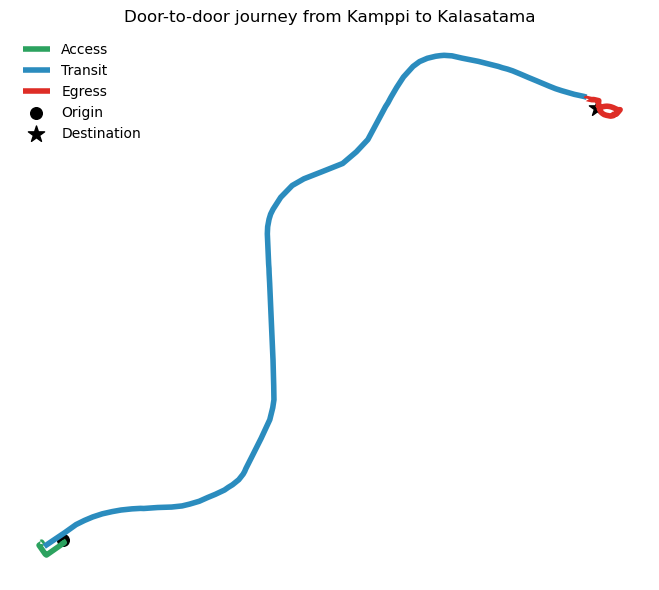

In [8]:
import matplotlib.pyplot as plt

route_points = gpd.GeoDataFrame(
    {"place": ["Kamppi", "Kalasatama"]},
    geometry=gpd.points_from_xy(
        [origin[1], destination[1]],
        [origin[0], destination[0]],
    ),
    crs="EPSG:4326",
)

leg_colours = {
    "access": "#2ca25f",
    "transit": "#2b8cbe",
    "egress": "#de2d26",
}

figure, axis = plt.subplots(figsize=(9, 6))

for leg_type, colour in leg_colours.items():
    selected_legs = route_legs["type"] == leg_type
    route_legs.loc[selected_legs].plot(
        ax=axis,
        color=colour,
        linewidth=4,
        label=leg_type.capitalize(),
    )

route_points.iloc[[0]].plot(
    ax=axis,
    color="black",
    marker="o",
    markersize=70,
    label="Origin",
)
route_points.iloc[[1]].plot(
    ax=axis,
    color="black",
    marker="*",
    markersize=150,
    label="Destination",
)

axis.set_title("Door-to-door journey from Kamppi to Kalasatama")
axis.set_axis_off()
axis.legend(loc="upper left", frameon=False)
figure.tight_layout()

In [9]:
network.annotate_emissions(journeys)

print(f"whole journey: {journey['emissions']:.0f} g CO2e")
for leg in journey["legs"]:
    if leg["type"] == "transit":
        print(
            f"  {leg['route_short_name']:>4}: "
            f"{leg['distance_m']:.0f} m, {leg['emissions']:.0f} g"
        )

whole journey: 102 g CO2e
    M1: 4091 m, 102 g


In [10]:
from cafein import TravelCostMatrix

origin_records = [
    ("kamppi", 24.93300, 60.16891),
    ("kallio", 24.95200, 60.18400),
]
origins = gpd.GeoDataFrame(
    origin_records,
    columns=["id", "longitude", "latitude"],
)
origin_points = gpd.points_from_xy(
    origins["longitude"],
    origins["latitude"],
)
origins = origins.set_geometry(
    origin_points,
    crs="EPSG:4326",
)

destination_records = [
    ("railway", 24.94140, 60.17190),
    ("kalasatama", 24.97800, 60.18700),
    ("punavuori", 24.93630, 60.16130),
]
destinations = gpd.GeoDataFrame(
    destination_records,
    columns=["id", "longitude", "latitude"],
)
destination_points = gpd.points_from_xy(
    destinations["longitude"],
    destinations["latitude"],
)
destinations = destinations.set_geometry(
    destination_points,
    crs="EPSG:4326",
)

In [11]:
destinations

,id,longitude,latitude,geometry
0,railway,24.9414,60.1719,POINT (24.9414 60.1719)
1,kalasatama,24.9780,60.1870,POINT (24.978 60.187)
2,punavuori,24.9363,60.1613,POINT (24.9363 60.1613)


In [12]:
matrix = TravelCostMatrix(
    network,
    origins,
    destinations,
    departure,
)
matrix

,from_id,to_id,travel_time,transfers,transit_distance_m,walk_distance_m,emissions
0,kamppi,railway,9,0,508.0,449.550667,12.700
1,kamppi,kalasatama,17,0,4091.0,536.917965,102.275
2,kamppi,punavuori,16,0,973.0,302.089383,89.516
3,kallio,railway,17,0,1465.0,767.550186,36.625
4,kallio,kalasatama,20,0,2070.0,858.030576,51.750
5,kallio,punavuori,26,1,2590.0,919.467566,64.750


In [13]:
from cafein import journey_frontier

frontier = journey_frontier(
    network,
    origin,
    destination,
    departure,
    departure_time_window=60,
    candidates="pareto",
)

frontier_rows = frontier.loc[frontier["frontier"]]
summary_columns = ["travel_time", "rides", "emissions"]

frontier_summary = frontier_rows[summary_columns]
frontier_summary = frontier_summary.drop_duplicates()
frontier_summary = frontier_summary.reset_index(drop=True)
frontier_summary


,travel_time,rides,emissions
0,16,1,102.275
1,19,1,89.575
2,36,1,62.700
3,44,1,49.325
4,45,2,48.750
5,57,1,24.450
6,58,1,22.150
7,59,1,21.950
8,60,1,15.950
9,68,0,0.000


,departure_s,arrival_s,travel_time,rides,emissions,frontier,journey
0,30644,31602,16,1,102.275,True,"{'departure_s': 30644, 'arrival_s': 31602, 'ri..."
1,30824,31782,16,1,102.275,True,"{'departure_s': 30824, 'arrival_s': 31782, 'ri..."
2,30944,31902,16,1,102.275,True,"{'departure_s': 30944, 'arrival_s': 31902, 'ri..."
3,31124,32082,16,1,102.275,True,"{'departure_s': 31124, 'arrival_s': 32082, 'ri..."
4,31244,32202,16,1,102.275,True,"{'departure_s': 31244, 'arrival_s': 32202, 'ri..."
...,...,...,...,...,...,...,...
136,33486,37050,59,1,21.950,True,"{'departure_s': 33486, 'arrival_s': 37050, 'ri..."
137,34199,37773,60,1,24.450,False,"{'departure_s': 34199, 'arrival_s': 37773, 'ri..."
138,33497,37098,60,1,15.950,True,"{'departure_s': 33497, 'arrival_s': 37098, 'ri..."
139,34157,37758,60,1,15.950,True,"{'departure_s': 34157, 'arrival_s': 37758, 'ri..."


In [14]:
origin

(60.16891, 24.933)

In [15]:
network.save("../networks/helsinki-region.cafein")
reloaded = TransportNetwork.load("../networks/helsinki-region.cafein")
reloaded.stop_count

saving the network:  50%|#####     | 1/2 [00:02<00:02,  2.00s/it]

loading the network:   0%|          | 0/2 [00:02<?, ?it/s]

8375

Building the network

In [16]:
import geopandas as gpd
import matplotlib.pyplot as plt

import cafein.sampledata.helsinki as helsinki

gtfs = helsinki.gtfs
osm = helsinki.osm_pbf
dem = helsinki.dem
population_grid_path = helsinki.population_grid

print("GTFS:", gtfs.name)
print("OpenStreetMap:", osm.name)
print("Elevation model:", dem.name)
print("Population grid:", population_grid_path.name)

GTFS: hsl_gtfs.zip
OpenStreetMap: helsinki_capital_region.osm.pbf
Elevation model: helsinki_dem_10m.tif
Population grid: hsy_population_grid_250m.gpkg


In [17]:
from cafein import TransportNetwork

timetable_only = TransportNetwork.from_gtfs(gtfs)
(
    timetable_only.stop_count,
    timetable_only.trip_count,
    timetable_only.transfer_count,
)

building the transit core from GTFS:   0%|          | 0/3 [00:02<?, ?it/s]

(8375, 335404, 0)

In [18]:
network = TransportNetwork.from_gtfs(
    gtfs,
    osm_pbf=osm,
    street_modes=(
        "walk",
        "bicycle",
        "e_scooter",
        "wheelchair",
        "car",
    ),
    dem=dem,
    dem_interval=25,
)
network.transfer_count, network.has_multimodal_streets, network.street_modes

building the transit core from GTFS:   0%|          | 0/3 [00:02<?, ?it/s]

reading the OSM walking network:   0%|          | 0/100 [00:02<?, ?it/s]

/tmp/marinflo/2640876/ipykernel_949012/1772940767.py:1: UserWarning: 1009 stop(s) are farther than 1600.0 m from the walking network and get no footpaths
  network = TransportNetwork.from_gtfs(


reading the OSM street network:  33%|###3      | 33.0/100 [00:02<00:04, 16.47it/s]

/tmp/marinflo/2640876/ipykernel_949012/1772940767.py:1: UserWarning: no country= given; using the Generic legal default speed limits for untagged ways
  network = TransportNetwork.from_gtfs(


(279166, True, ('walk', 'bicycle', 'e_scooter', 'wheelchair', 'car'))

The two street sections serve different purposes. The walking graph preserves the established walking-transfer and door-to-door behaviour. The multimodal graph supports StreetLegPolicy choices such as cycling to a stop or using a shared e-scooter after alighting. It lets a wheelchair traveller use the wheelchair street profile for direct routes and door-to-door journey parts. The car profile supplies the driving part of park-and-ride access.

In [19]:
print("stops:        ", network.stop_count)
print("trips:        ", network.trip_count)
print("patterns:     ", network.pattern_count)
print("transfers:    ", network.transfer_count)
print("street modes: ", network.street_modes)
print("DEM coverage:  ", f"{network.multimodal_elevation_metadata['coverage']:.1%}")


stops:         8375
trips:         335404
patterns:      1694
transfers:     279166
street modes:  ('walk', 'bicycle', 'e_scooter', 'wheelchair', 'car')
DEM coverage:   99.9%


In [20]:
service_start, service_end = network.service_window
daily_trip_counts = network.daily_trip_counts

busiest_date = daily_trip_counts.idxmax()
busiest_trip_count = daily_trip_counts.loc[busiest_date]

print(f"Service starts: {service_start}")
print(f"Service ends:   {service_end}")
print(f"Busiest date:   {busiest_date.date()} ({busiest_trip_count:,} trips)")


Service starts: 2026-08-20
Service ends:   2026-10-18
Busiest date:   2026-08-28 (24,234 trips)


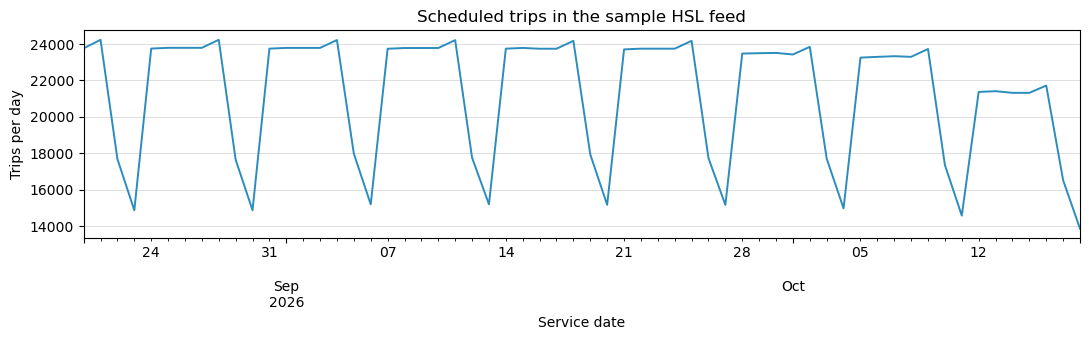

In [21]:
figure, axis = plt.subplots(figsize=(11, 3.5))

daily_trip_counts.plot(
    ax=axis,
    color="#2B8CBE",
    linewidth=1.4,
)

axis.set_title("Scheduled trips in the sample HSL feed")
axis.set_xlabel("Service date")
axis.set_ylabel("Trips per day")
axis.grid(axis="y", color="#D9D9D9", linewidth=0.6)
figure.tight_layout()

In [22]:
stops = network.stops_gdf
routes = network.routes_gdf
streets = network.streets_gdf
connectors = network.connectors_gdf

print(f"Stops:      {len(stops):,}")
print(f"Routes:     {len(routes):,}")
print(f"Streets:    {len(streets):,}")
print(f"Connectors: {len(connectors):,}")

routes.head()

Stops:      8,375
Routes:     464
Streets:    1,644,890
Connectors: 7,366


,id,name,route_type,geometry_provenance,geometry
0,1001,1,0,shape,"MULTILINESTRING ((24.9633 60.18803, 24.96346 6..."
1,1001H,1H,0,shape,"MULTILINESTRING ((24.96087 60.19732, 24.96088 ..."
2,1001T,1T,0,shape,"MULTILINESTRING ((24.92695 60.182, 24.92707 60..."
3,1002,2,0,shape,"MULTILINESTRING ((24.92658 60.18229, 24.92642 ..."
4,1002H,2H,0,shape,"MULTILINESTRING ((24.93663 60.20138, 24.93385 ..."


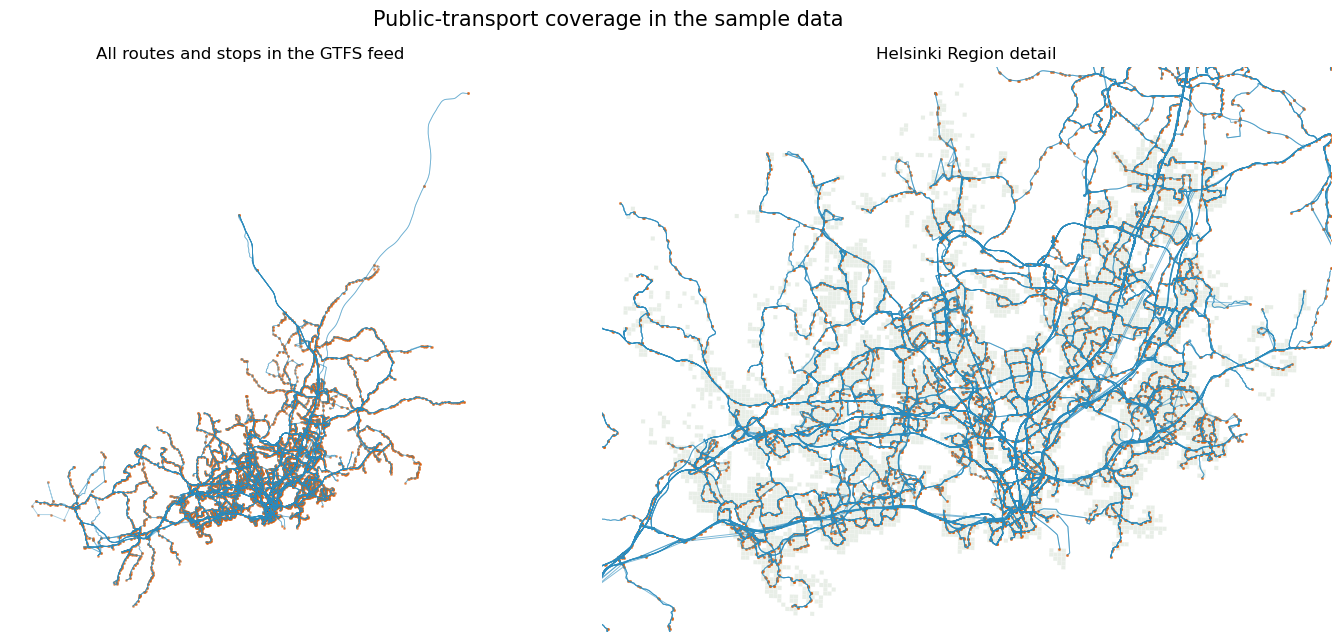

In [23]:
population_grid = gpd.read_file(population_grid_path)
map_crs = population_grid.crs

# Routes without geometry remain useful records, but they cannot be plotted.
mapped_routes = routes.loc[routes.geometry.notna()].to_crs(map_crs)
mapped_stops = stops.loc[stops.geometry.notna()].to_crs(map_crs)

figure, axes = plt.subplots(
    ncols=2,
    figsize=(15, 6.5),
)

mapped_routes.plot(
    ax=axes[0],
    color="#2B8CBE",
    linewidth=0.6,
    alpha=0.45,
)
mapped_stops.plot(
    ax=axes[0],
    color="#D95F0E",
    markersize=1.2,
    alpha=0.5,
)
axes[0].set_title("All routes and stops in the GTFS feed")

population_grid.plot(
    ax=axes[1],
    color="#E8EEE7",
    edgecolor="white",
    linewidth=0.1,
)
mapped_routes.plot(
    ax=axes[1],
    color="#2B8CBE",
    linewidth=0.7,
    alpha=0.6,
)
mapped_stops.plot(
    ax=axes[1],
    color="#D95F0E",
    markersize=1.5,
    alpha=0.65,
)

min_x, min_y, max_x, max_y = population_grid.total_bounds
x_padding = (max_x - min_x) * 0.03
y_padding = (max_y - min_y) * 0.03
axes[1].set_xlim(min_x - x_padding, max_x + x_padding)
axes[1].set_ylim(min_y - y_padding, max_y + y_padding)
axes[1].set_title("Helsinki Region detail")

for axis in axes:
    axis.set_axis_off()

figure.suptitle("Public-transport coverage in the sample data", fontsize=15)
figure.tight_layout()

In [24]:
network.save("../networks/helsinki-region.cafein")
network = TransportNetwork.load("../networks/helsinki-region.cafein")
network.stop_count, network.street_modes

saving the network:  50%|#####     | 1/2 [00:02<00:02,  2.00s/it]

loading the network:   0%|          | 0/2 [00:02<?, ?it/s]

(8375, ('walk', 'bicycle', 'e_scooter', 'wheelchair', 'car'))